# Segmentación de clientes con aprendizaje no supervisado
## Dataset *Wholesale Customers* — UCI Machine Learning Repository

En esta práctica recorreremos el proceso completo: obtener los datos, reconocer sus filas y columnas, decidir qué variables usar, prepararlas y aplicar un algoritmo de agrupamiento.

**Pregunta guía:** ¿podemos encontrar grupos de clientes con patrones de gasto parecidos en distintas categorías de productos?

Al final veremos también cómo buscar clientes cercanos con **KNN**. KNN y K-Means se parecen en que usan distancias, pero resuelven tareas distintas: KNN suele predecir una clase conocida (aprendizaje supervisado); K-Means crea grupos sin etiquetas (aprendizaje no supervisado).


### Qué vamos a aprender

1. Descargar y reconocer una tabla de datos real.
2. Identificar las variables y seleccionar las adecuadas para la pregunta.
3. Transformar y escalar datos para que las distancias sean comparables.
4. Agrupar clientes con K-Means y describir los grupos con tablas y gráficas.
5. Comparar la idea de K-Means con una búsqueda de vecinos cercanos.

**Importante:** en clustering no tenemos una columna `y` con la respuesta correcta. El algoritmo construye grupos a partir de las semejanzas que encuentra en las variables seleccionadas.


## 1. Importar las herramientas

Usaremos pandas para trabajar con tablas, seaborn y matplotlib para visualizar, y scikit-learn para preparar los datos, agruparlos y buscar vecinos.

Si hace falta instalar paquetes en el entorno del curso, ejecutar en la terminal: `python -m pip install pandas numpy matplotlib seaborn scikit-learn`.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)


## 2. Obtener los datos

El dataset describe el gasto anual de clientes de un distribuidor mayorista. La fuente es UCI. El archivo CSV se lee directamente desde su repositorio; conserva los encabezados publicados por UCI.

Fuente y descripción: [UCI — Wholesale customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers).


In [4]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"

datos = pd.read_csv(url)
columnas = datos.columns.tolist()
print("Datos descargados correctamente.")


Datos descargados correctamente.


Si la descarga en línea falla durante la clase, descarguen el CSV desde la página de UCI y sustituyan `url` por la ruta local del archivo. El resto del notebook se mantiene igual.

## 3. Reconocer la estructura

Antes de modelar, observamos una muestra y preguntamos: ¿cuántas filas y columnas hay?, ¿qué tipos de datos aparecen?, ¿hay valores faltantes?

In [5]:
display(datos.head())
print(f"Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}")
datos.info()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Filas: 440 | Columnas: 8
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
resumen_calidad = pd.DataFrame({
    "tipo de dato": datos.dtypes.astype(str),
    "valores faltantes": datos.isna().sum(),
    "valores distintos": datos.nunique()
})
display(resumen_calidad)
print("Filas duplicadas:", datos.duplicated().sum())


,tipo de dato,valores faltantes,valores distintos
Channel,int64,0,2
Region,int64,0,3
Fresh,int64,0,433
Milk,int64,0,421
Grocery,int64,0,430
Frozen,int64,0,426
Detergents_Paper,int64,0,417
Delicassen,int64,0,403


Filas duplicadas: 0


In [7]:
display(datos.describe().T.round(1))


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.3,0.5,1.0,1.0,1.0,2.0,2.0
Region,440.0,2.5,0.8,1.0,2.0,3.0,3.0,3.0
Fresh,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0
Milk,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0
Grocery,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0
Frozen,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0
Detergents_Paper,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0
Delicassen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0


**Lectura inicial:** cada fila representa un cliente; cada columna, una característica del cliente. Las columnas de categorías de compra contienen importes anuales. Los valores de gasto son muy distintos entre clientes, por lo que conviene revisar sus distribuciones antes de calcular distancias.

## 4. Identificar las variables

Primero separamos variables de identificación, variables categóricas descriptivas y variables numéricas de gasto. Esta decisión depende de la pregunta que queremos responder.

In [8]:
significado = pd.DataFrame({
    "Variable": columnas,
    "Qué representa": [
        "Canal de compra (1 = Horeca, 2 = Retail)",
        "Región (1 = Lisboa, 2 = Oporto, 3 = otra región)",
        "Gasto anual en productos frescos",
        "Gasto anual en leche",
        "Gasto anual en abarrotes",
        "Gasto anual en congelados",
        "Gasto anual en detergentes y papel",
        "Gasto anual en delicatessen"
    ],
    "Tipo para el análisis": [
        "Categórica codificada", "Categórica codificada", "Numérica de gasto",
        "Numérica de gasto", "Numérica de gasto", "Numérica de gasto",
        "Numérica de gasto", "Numérica de gasto"
    ]
})
display(significado)


,Variable,Qué representa,Tipo para el análisis
0,Channel,"Canal de compra (1 = Horeca, 2 = Retail)",Categórica codificada
1,Region,"Región (1 = Lisboa, 2 = Oporto, 3 = otra región)",Categórica codificada
2,Fresh,Gasto anual en productos frescos,Numérica de gasto
3,Milk,Gasto anual en leche,Numérica de gasto
4,Grocery,Gasto anual en abarrotes,Numérica de gasto
5,Frozen,Gasto anual en congelados,Numérica de gasto
6,Detergents_Paper,Gasto anual en detergentes y papel,Numérica de gasto
7,Delicassen,Gasto anual en delicatessen,Numérica de gasto


### ¿Qué columnas usaríamos para agrupar?

Usaremos las seis categorías de gasto porque la pregunta trata de **patrones de compra**. Dejamos fuera `Channel` y `Region`: son códigos de categorías, y tratarlos como números en una distancia daría un significado numérico engañoso (por ejemplo, que la región 3 sea “más” que la región 1). Más adelante podemos usar esas columnas para describir los grupos encontrados.

El archivo de UCI no incluye un identificador de cliente. El número de fila de pandas sirve para localizar un registro durante la práctica, pero no es una variable del dataset ni se usa en el modelo.


In [9]:
variables_gasto = [
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"
]
X_original = datos[variables_gasto].copy()
display(X_original.head())
print("Forma de la matriz que analizaremos:", X_original.shape)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Forma de la matriz que analizaremos: (440, 6)


## 5. Explorar y preparar los gastos

Las variables se expresan en importes anuales. Además, algunos clientes gastan muchísimo más que otros. Como K-Means compara distancias, una variable con números grandes puede dominar el cálculo. Primero observamos las distribuciones.

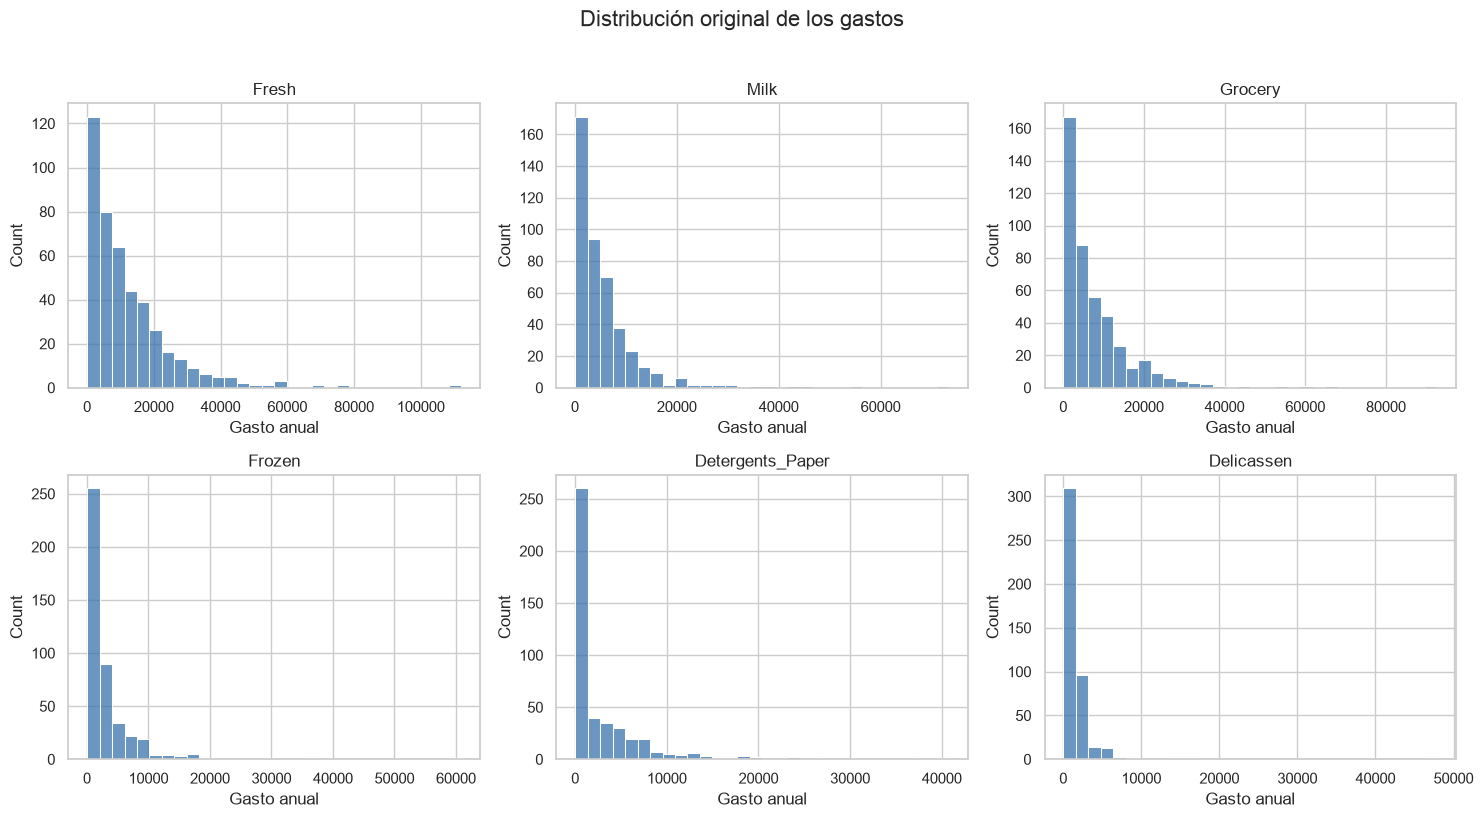

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, columna in zip(axes.flat, variables_gasto):
    sns.histplot(data=X_original, x=columna, bins=30, ax=ax, color="#3973ac")
    ax.set_title(columna)
    ax.set_xlabel("Gasto anual")
plt.suptitle("Distribución original de los gastos", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


Las distribuciones suelen tener una cola larga: pocos clientes registran gastos muy altos. Aplicaremos `log1p(x)`, que calcula `log(1 + x)`. Comprime las distancias entre valores grandes y permite conservar gastos iguales a cero. Después estandarizamos las variables para que todas tengan una escala comparable.

La transformación no cambia la unidad original de la tabla; crea una matriz de trabajo para el algoritmo.

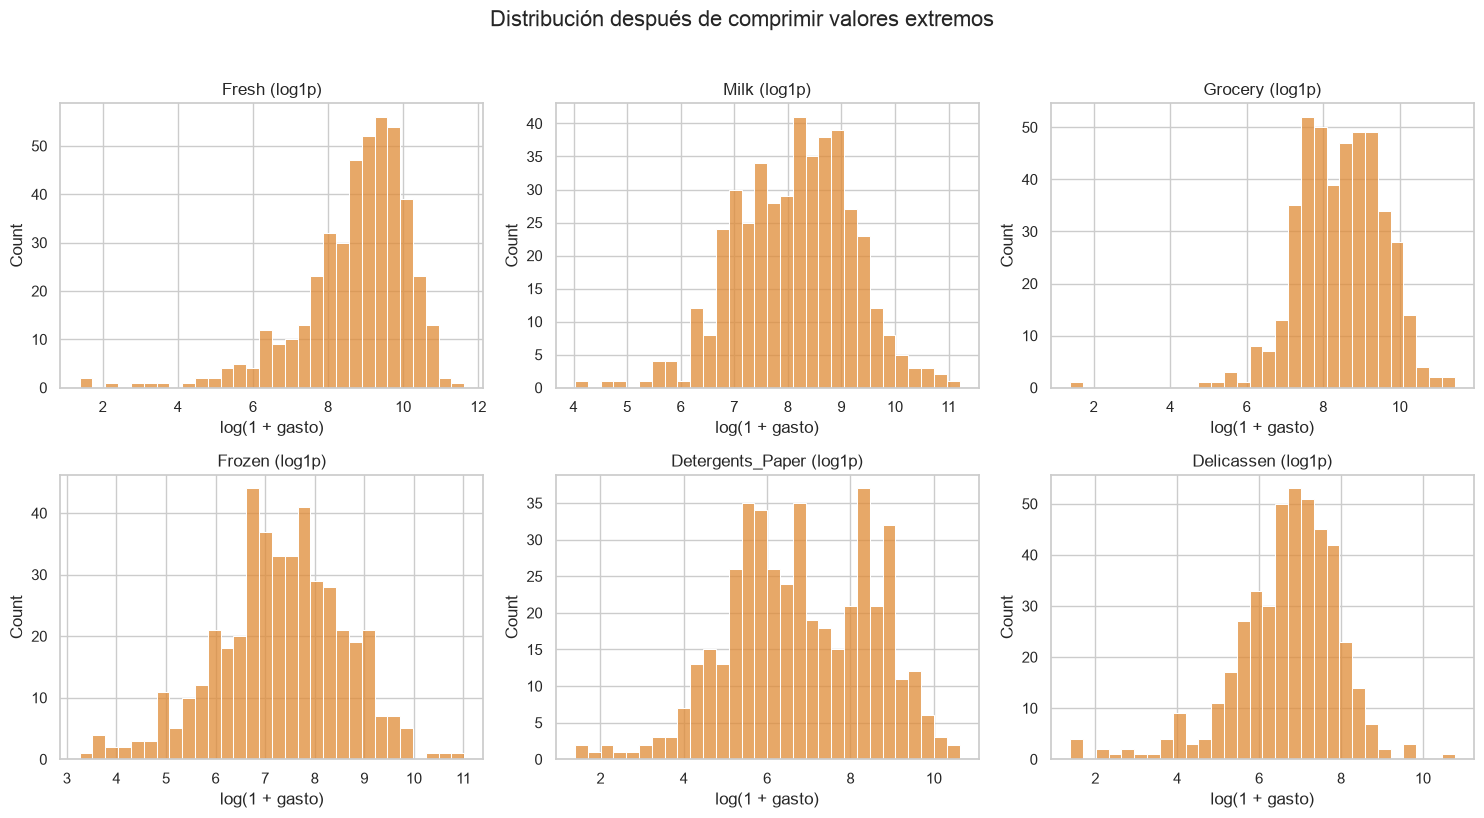

In [11]:
X_log = np.log1p(X_original)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, columna in zip(axes.flat, variables_gasto):
    sns.histplot(data=X_log, x=columna, bins=30, ax=ax, color="#e08b36")
    ax.set_title(f"{columna} (log1p)")
    ax.set_xlabel("log(1 + gasto)")
plt.suptitle("Distribución después de comprimir valores extremos", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


In [12]:
escalador = StandardScaler()
X_preparado = escalador.fit_transform(X_log)

# Volvemos a DataFrame para conservar los nombres de las variables
X_preparado = pd.DataFrame(X_preparado, columns=variables_gasto, index=datos.index)
display(X_preparado.head().round(2))
print("Promedio por variable (aprox. 0):")
display(X_preparado.mean().round(2).to_frame("promedio"))
print("Desviación estándar por variable (aprox. 1):")
display(X_preparado.std(ddof=0).round(2).to_frame("desviación estándar"))


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.49,0.98,0.44,-1.51,0.64,0.41
1,0.09,0.99,0.65,0.13,0.77,0.63
2,0.02,0.89,0.45,0.38,0.80,1.78
3,0.52,-0.96,-0.08,1.14,-0.33,0.63
4,0.88,0.44,0.40,0.76,0.40,1.46


Promedio por variable (aprox. 0):


,promedio
Fresh,0.0
Milk,-0.0
Grocery,-0.0
Frozen,0.0
Detergents_Paper,-0.0
Delicassen,-0.0


Desviación estándar por variable (aprox. 1):


,desviación estándar
Fresh,1.0
Milk,1.0
Grocery,1.0
Frozen,1.0
Detergents_Paper,1.0
Delicassen,1.0


**Qué representa cada paso:** `log1p` reduce el efecto de gastos extremadamente altos; `StandardScaler` centra cada variable alrededor de 0 y la expresa en desviaciones estándar. Así, ninguna categoría gana peso solo por tener cifras mayores. No hay variable objetivo ni división entrenamiento/prueba porque aquí no estamos prediciendo una etiqueta conocida.


## 6. Explorar cuántos grupos usar

K-Means necesita que indiquemos cuántos grupos `k` debe buscar. La curva de inercia (método del codo) muestra qué tan compactos quedan los grupos. La puntuación silhouette resume qué tan separados y compactos están; valores mayores suelen ser mejores, aunque no determinan por sí solos la respuesta correcta.


In [13]:
resultados_k = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_preparado)
    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_preparado, etiquetas)
    })

metricas_k = pd.DataFrame(resultados_k)
display(metricas_k.round(3))


,k,inercia,silhouette
0,2,1844.064,0.290
1,3,1553.421,0.259
2,4,1386.863,0.188
3,5,1266.149,0.192
4,6,1174.759,0.201
5,7,1086.359,0.196
6,8,1028.486,0.185


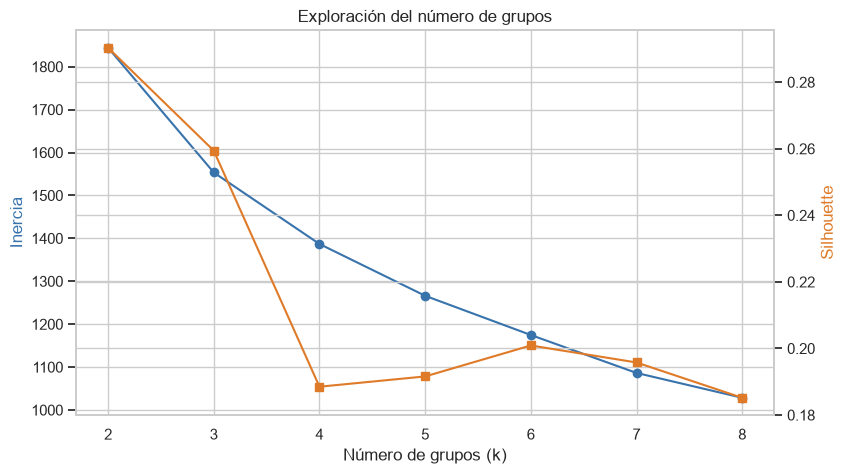

In [21]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(metricas_k["k"], metricas_k["inercia"], marker="o", color="#3973ac")
ax1.set_xlabel("Número de grupos (k)")
ax1.set_ylabel("Inercia", color="#3973ac")
ax1.set_title("Exploración del número de grupos")
ax2 = ax1.twinx()
ax2.plot(metricas_k["k"], metricas_k["silhouette"], marker="s", color="#df7b28")
ax2.set_ylabel("Silhouette", color="#df7b28")
plt.show()


Para esta demostración continuaremos con **3 grupos** para poder practicar su comparación e interpretación. En un análisis real justificaríamos `k` observando las métricas, el propósito del negocio y si los grupos resultan útiles; no existe un número universalmente correcto. Si al discutir la gráfica prefieren otro valor, cambien `k_elegido` en la celda siguiente y vuelvan a ejecutar las celdas posteriores.


## 7. Ajustar K-Means y asignar grupos

Cada cliente recibe una etiqueta de grupo (`0`, `1` o `2`). Esos números son nombres asignados por el algoritmo, no un orden de “peor a mejor”.

In [14]:
k_elegido = 3
modelo_kmeans = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
datos["Cluster"] = modelo_kmeans.fit_predict(X_preparado)

conteo_grupos = datos["Cluster"].value_counts().sort_index().rename("clientes")
conteo_grupos = conteo_grupos.to_frame()
conteo_grupos["porcentaje"] = (conteo_grupos["clientes"] / len(datos) * 100).round(1)
display(conteo_grupos)


,clientes,porcentaje
Cluster,,
0,80,18.2
1,147,33.4
2,213,48.4


In [16]:
# Perfil de cada grupo usando medianas en la escala original, fácil de interpretar
perfil_mediano = datos.groupby("Cluster")[variables_gasto].median().round(0).astype(int)
display(perfil_mediano)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,1492,6300,10502,376,4218,434
1,12126,7184,9965,2005,3378,2005
2,9612,1601,2155,2121,274,686


La **mediana** resume el cliente típico de cada grupo y es menos sensible que el promedio a unos pocos gastos muy altos. La tabla está en la escala original de gasto para facilitar su lectura. Compara columnas y grupos: ¿qué categorías distinguen más a cada grupo?

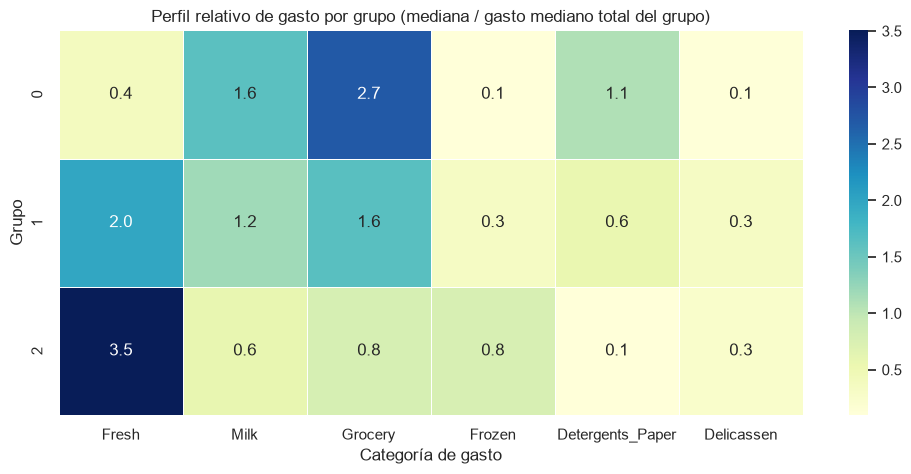

In [17]:
perfil_visual = perfil_mediano.copy()
perfil_relativo = perfil_visual.div(perfil_visual.mean(axis=1), axis=0)

plt.figure(figsize=(12, 5))
sns.heatmap(perfil_relativo, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5)
plt.title("Perfil relativo de gasto por grupo (mediana / gasto mediano total del grupo)")
plt.xlabel("Categoría de gasto")
plt.ylabel("Grupo")
plt.show()


En el mapa de calor, los valores más altos indican que esa categoría está por encima del gasto mediano de las categorías del mismo grupo; los valores más bajos, por debajo. Es una vista relativa para comparar perfiles, no un porcentaje del total de ventas.


In [18]:
# Comparar el canal y la región después de formar los grupos (solo para describirlos)
canal_por_grupo = pd.crosstab(datos["Cluster"], datos["Channel"], normalize="index").mul(100).round(1)
region_por_grupo = pd.crosstab(datos["Cluster"], datos["Region"], normalize="index").mul(100).round(1)
print("Porcentaje de clientes por canal dentro de cada grupo:")
display(canal_por_grupo)
print("Porcentaje de clientes por región dentro de cada grupo:")
display(region_por_grupo)


Porcentaje de clientes por canal dentro de cada grupo:


Channel,1,2
Cluster,,
0,40.0,60.0
1,38.1,61.9
2,98.6,1.4


Porcentaje de clientes por región dentro de cada grupo:


Region,1,2,3
Cluster,,,
0,17.5,12.5,70.0
1,15.6,7.5,76.9
2,18.8,12.2,69.0


## 8. Visualizar los grupos en dos dimensiones

El modelo utilizó las seis variables de gasto. Para dibujar cada cliente en una hoja necesitamos reducirlas a dos coordenadas. PCA crea dos combinaciones que conservan la mayor variación posible; esta gráfica ayuda a observar la estructura, pero es una proyección y puede ocultar diferencias presentes en las seis dimensiones.


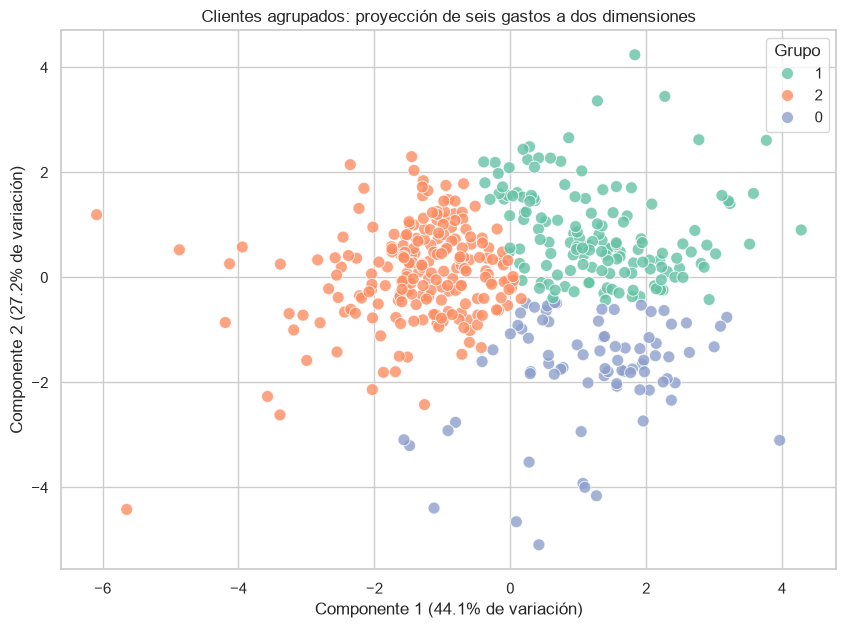

Variación representada en la gráfica: 71.3%


In [19]:
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_preparado)
visualizacion = pd.DataFrame(coordenadas, columns=["Componente 1", "Componente 2"])
visualizacion["Cluster"] = datos["Cluster"].astype(str).values

plt.figure(figsize=(10, 7))
sns.scatterplot(data=visualizacion, x="Componente 1", y="Componente 2", hue="Cluster",
                palette="Set2", s=75, alpha=.8)
plt.title("Clientes agrupados: proyección de seis gastos a dos dimensiones")
plt.xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}% de variación)")
plt.ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}% de variación)")
plt.legend(title="Grupo")
plt.show()
print(f"Variación representada en la gráfica: {pca.explained_variance_ratio_.sum()*100:.1f}%")


## 9. ¿Dónde entra KNN? Buscar clientes cercanos

**KNN no es el algoritmo que creó los grupos.** En clasificación, KNN usa las etiquetas de los vecinos para asignar una etiqueta a un caso nuevo. Como aquí no contamos con una etiqueta correcta que predecir, no entrenaremos un clasificador KNN.

Sí podemos usar `NearestNeighbors` (búsqueda de los *k* vecinos más cercanos) para localizar clientes con perfiles de gasto similares. Esto es una consulta de vecinos, no una segmentación: cada cliente conserva su grupo de K-Means y solo mostramos quiénes están cerca de un cliente elegido.


In [20]:
# Elegimos un cliente solo para mostrar cómo funciona una consulta de vecinos
indice_cliente = 0
numero_vecinos = 6  # incluye al propio cliente; luego lo quitaremos de la tabla

buscador = NearestNeighbors(n_neighbors=numero_vecinos, metric="euclidean")
buscador.fit(X_preparado)
distancias, indices = buscador.kneighbors(X_preparado.iloc[[indice_cliente]])

vecinos = datos.iloc[indices[0]].copy()
vecinos["distancia_estandarizada"] = distancias[0]
vecinos = vecinos[vecinos.index != datos.index[indice_cliente]]
vecinos.insert(0, "Fila", vecinos.index + 1)
print(f"Fila consultada: {indice_cliente + 1} | Grupo K-Means: {datos.loc[indice_cliente, 'Cluster']}")
display(vecinos[["Fila", "Cluster"] + variables_gasto + ["distancia_estandarizada"]].round(2))


Fila consultada: 1 | Grupo K-Means: 1


,Fila,Cluster,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,distancia_estandarizada
14,15,1,24653,9465,12091,294,5058,2168,0.85
59,60,0,6137,5360,8040,129,3084,1603,0.85
180,181,1,12356,6036,8887,402,1382,2794,0.96
417,418,0,5065,5499,11055,364,3485,1063,1.00
5,6,1,9413,8259,5126,666,1795,1451,1.01


En general, los vecinos más próximos tendrán patrones de gasto parecidos, pero no tienen que compartir siempre el mismo grupo: K-Means divide el espacio en regiones, y la lista de vecinos responde otra pregunta (“¿quién está más cerca de este cliente?”).


## 10. Resumen del proceso

| Etapa | Qué hicimos | Para qué sirvió |
|---|---|---|
| Obtención | Leímos el CSV público de UCI | Trabajar con datos reales y rastrear su origen |
| Reconocimiento | Revisamos forma, tipos, faltantes, duplicados y estadísticas | Entender qué contiene la tabla |
| Selección | Usamos seis categorías de gasto; excluimos identificador y códigos de categorías del cálculo | Alinear las variables con la pregunta |
| Preparación | Aplicamos `log1p` y estandarización | Hacer más comparables las distancias |
| Agrupamiento | Ajustamos K-Means sin una columna objetivo | Encontrar perfiles de clientes parecidos |
| Interpretación | Comparamos medianas, tamaños y gráficas | Describir los grupos en contexto |
| Vecinos | Consultamos clientes cercanos con `NearestNeighbors` | Ilustrar KNN/vecindad sin confundirlo con clustering |

### Ideas clave

- En aprendizaje no supervisado no proporcionamos etiquetas objetivo para que el algoritmo las aprenda.
- K-Means necesita variables numéricas comparables y requiere especificar el número de grupos.
- La preparación de datos influye en las distancias y, por tanto, en los grupos encontrados.
- Las etiquetas `0`, `1`, `2` no tienen jerarquía; describimos los grupos observando sus características.
- KNN suele ser supervisado cuando predice una clase; buscar vecinos cercanos por sí solo no equivale a crear clusters.


### Preguntas para comentar en clase

1. ¿Por qué no usamos `CustomerID` para calcular los grupos?
2. ¿Qué problema habría si una categoría tuviera cifras mucho mayores que las demás y no escaláramos las variables?
3. ¿Qué diferencias observan entre los perfiles de gasto de los grupos?
4. ¿La gráfica PCA permite ver toda la información usada por K-Means?
5. ¿En qué se diferencia la consulta de vecinos cercanos de la creación de grupos?
6. ¿Qué otras variables o transformaciones probarían para cambiar la segmentación?
